In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("hotel_bookings.csv")

print(df.head())

          hotel  is_canceled  lead_time  arrival_date_year arrival_date_month  \
0  Resort Hotel            0        342               2015               July   
1  Resort Hotel            0        737               2015               July   
2  Resort Hotel            0          7               2015               July   
3  Resort Hotel            0         13               2015               July   
4  Resort Hotel            0         14               2015               July   

   arrival_date_week_number  arrival_date_day_of_month  \
0                        27                          1   
1                        27                          1   
2                        27                          1   
3                        27                          1   
4                        27                          1   

   stays_in_weekend_nights  stays_in_week_nights  adults  ...  deposit_type  \
0                        0                     0       2  ...    No Deposit   
1     

# Basic data understanding

In [2]:
# Dataset shape
print("Shape:", df.shape)

# Column names
print(df.columns)

# Dataset information
df.info()

# Statistical summary
print(df.describe())

# Data types
print(df.dtypes)

Shape: (119390, 32)
Index(['hotel', 'is_canceled', 'lead_time', 'arrival_date_year',
       'arrival_date_month', 'arrival_date_week_number',
       'arrival_date_day_of_month', 'stays_in_weekend_nights',
       'stays_in_week_nights', 'adults', 'children', 'babies', 'meal',
       'country', 'market_segment', 'distribution_channel',
       'is_repeated_guest', 'previous_cancellations',
       'previous_bookings_not_canceled', 'reserved_room_type',
       'assigned_room_type', 'booking_changes', 'deposit_type', 'agent',
       'company', 'days_in_waiting_list', 'customer_type', 'adr',
       'required_car_parking_spaces', 'total_of_special_requests',
       'reservation_status', 'reservation_status_date'],
      dtype='object')
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                 

# Data cleaning

In [3]:
# Check missing values
print(df.isnull().sum())

# Check duplicate records
print("Duplicates:", df.duplicated().sum())

# Remove duplicate records
df = df.drop_duplicates()

# Fill missing values
df['children'] = df['children'].fillna(df['children'].median())
df['country'] = df['country'].fillna('Unknown')
df['agent'] = df['agent'].fillna(-1)
df['company'] = df['company'].fillna(-1)

# Check missing values again
print(df.isnull().sum())

hotel                                  0
is_canceled                            0
lead_time                              0
arrival_date_year                      0
arrival_date_month                     0
arrival_date_week_number               0
arrival_date_day_of_month              0
stays_in_weekend_nights                0
stays_in_week_nights                   0
adults                                 0
children                               4
babies                                 0
meal                                   0
country                              488
market_segment                         0
distribution_channel                   0
is_repeated_guest                      0
previous_cancellations                 0
previous_bookings_not_canceled         0
reserved_room_type                     0
assigned_room_type                     0
booking_changes                        0
deposit_type                           0
agent                              16340
company         

# Univariate analysis

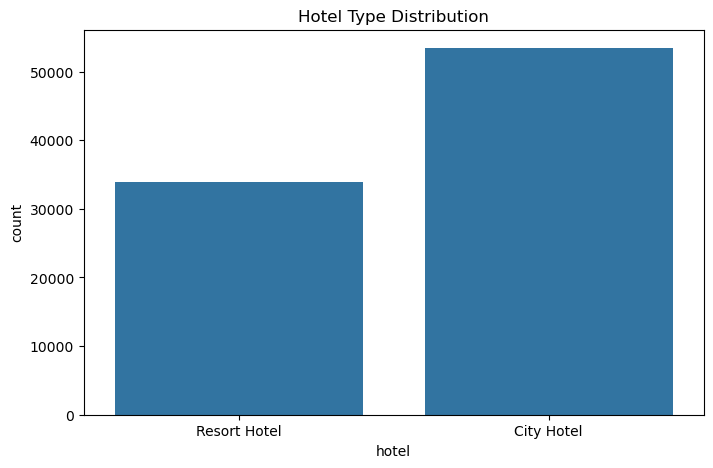

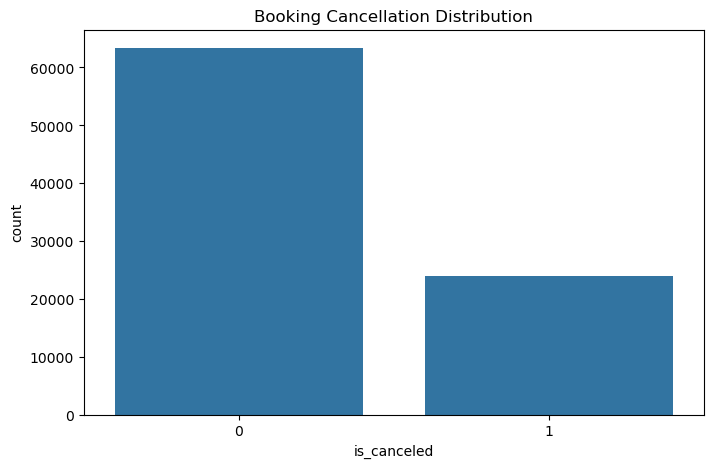

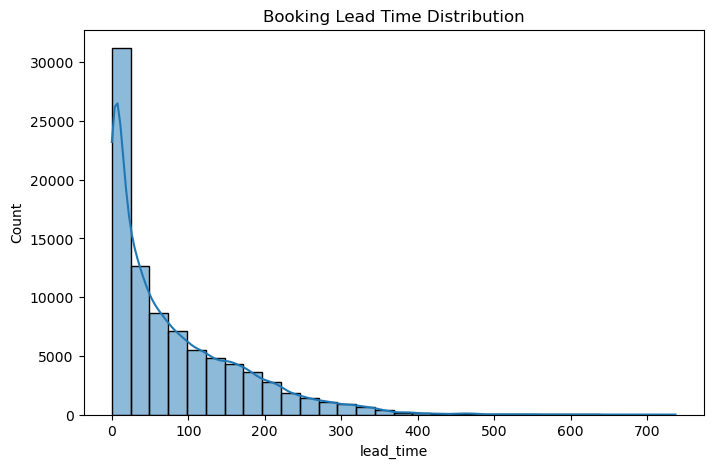

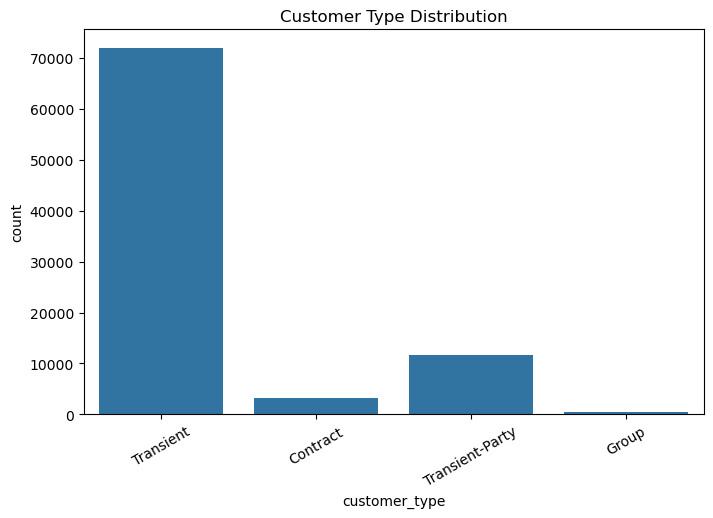

In [4]:
# Hotel type distribution
plt.figure(figsize=(8,5))
sns.countplot(x='hotel', data=df)
plt.title("Hotel Type Distribution")
plt.show()

# Booking cancellation distribution
plt.figure(figsize=(8,5))
sns.countplot(x='is_canceled', data=df)
plt.title("Booking Cancellation Distribution")
plt.show()

# Lead time distribution
plt.figure(figsize=(8,5))
sns.histplot(df['lead_time'], bins=30, kde=True)
plt.title("Booking Lead Time Distribution")
plt.show()

# Customer type distribution
plt.figure(figsize=(8,5))
sns.countplot(x='customer_type', data=df)
plt.title("Customer Type Distribution")
plt.xticks(rotation=30)
plt.show()

# Bivariate analysis

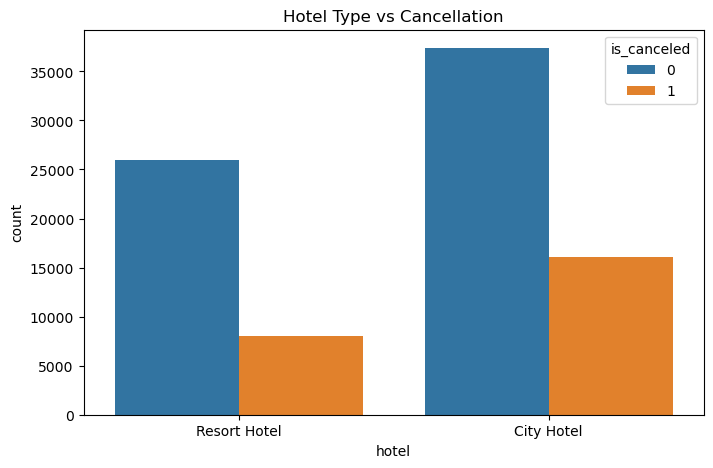

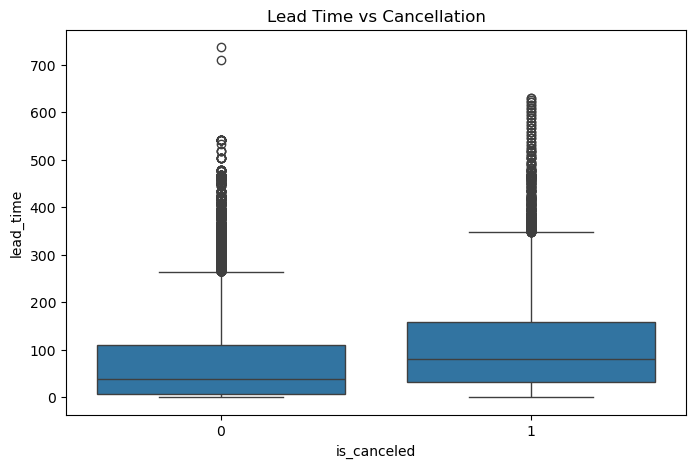

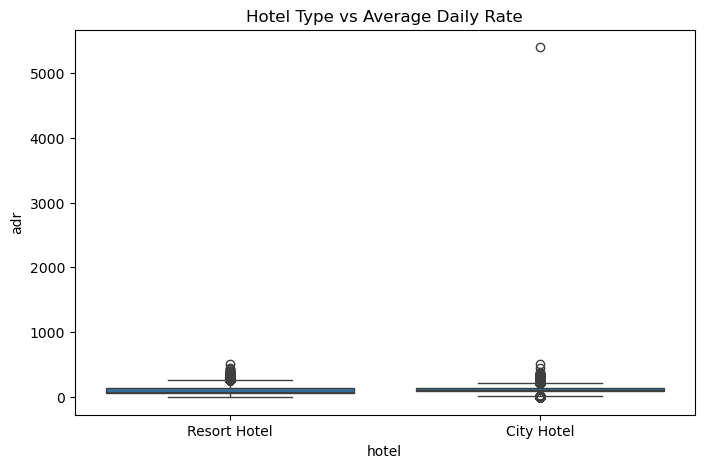

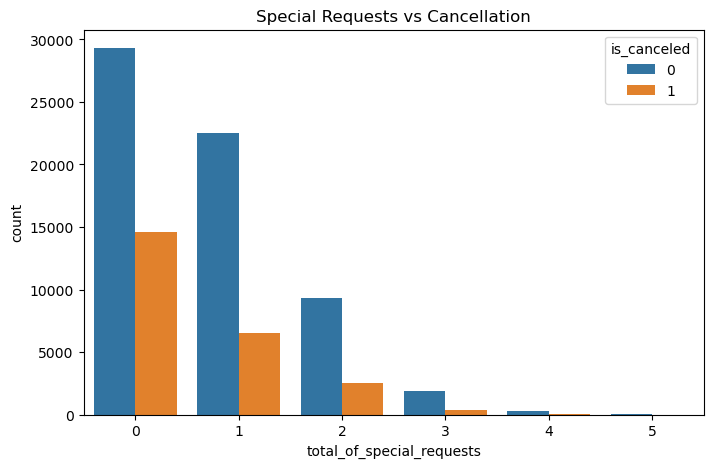

In [5]:
# Hotel type vs cancellation
plt.figure(figsize=(8,5))
sns.countplot(x='hotel', hue='is_canceled', data=df)
plt.title("Hotel Type vs Cancellation")
plt.show()

# Lead time vs cancellation
plt.figure(figsize=(8,5))
sns.boxplot(x='is_canceled', y='lead_time', data=df)
plt.title("Lead Time vs Cancellation")
plt.show()

# Hotel type vs average daily rate
plt.figure(figsize=(8,5))
sns.boxplot(x='hotel', y='adr', data=df)
plt.title("Hotel Type vs Average Daily Rate")
plt.show()

# Special requests vs cancellation
plt.figure(figsize=(8,5))
sns.countplot(x='total_of_special_requests',
              hue='is_canceled', data=df)
plt.title("Special Requests vs Cancellation")
plt.show()

# Correlation analysis

                                is_canceled  lead_time  arrival_date_year  \
is_canceled                        1.000000   0.184806           0.088030   
lead_time                          0.184806   1.000000           0.139135   
arrival_date_year                  0.088030   0.139135           1.000000   
arrival_date_week_number           0.001443   0.101150          -0.514228   
arrival_date_day_of_month          0.005328   0.009866          -0.010023   
stays_in_weekend_nights            0.060191   0.235145           0.005144   
stays_in_week_nights               0.082928   0.310129           0.003645   
adults                             0.081816   0.140493           0.038619   
children                           0.067369   0.028650           0.041158   
babies                            -0.020543  -0.003614          -0.023334   
is_repeated_guest                 -0.089643  -0.147003           0.024343   
previous_cancellations             0.051468   0.005375          -0.054212   

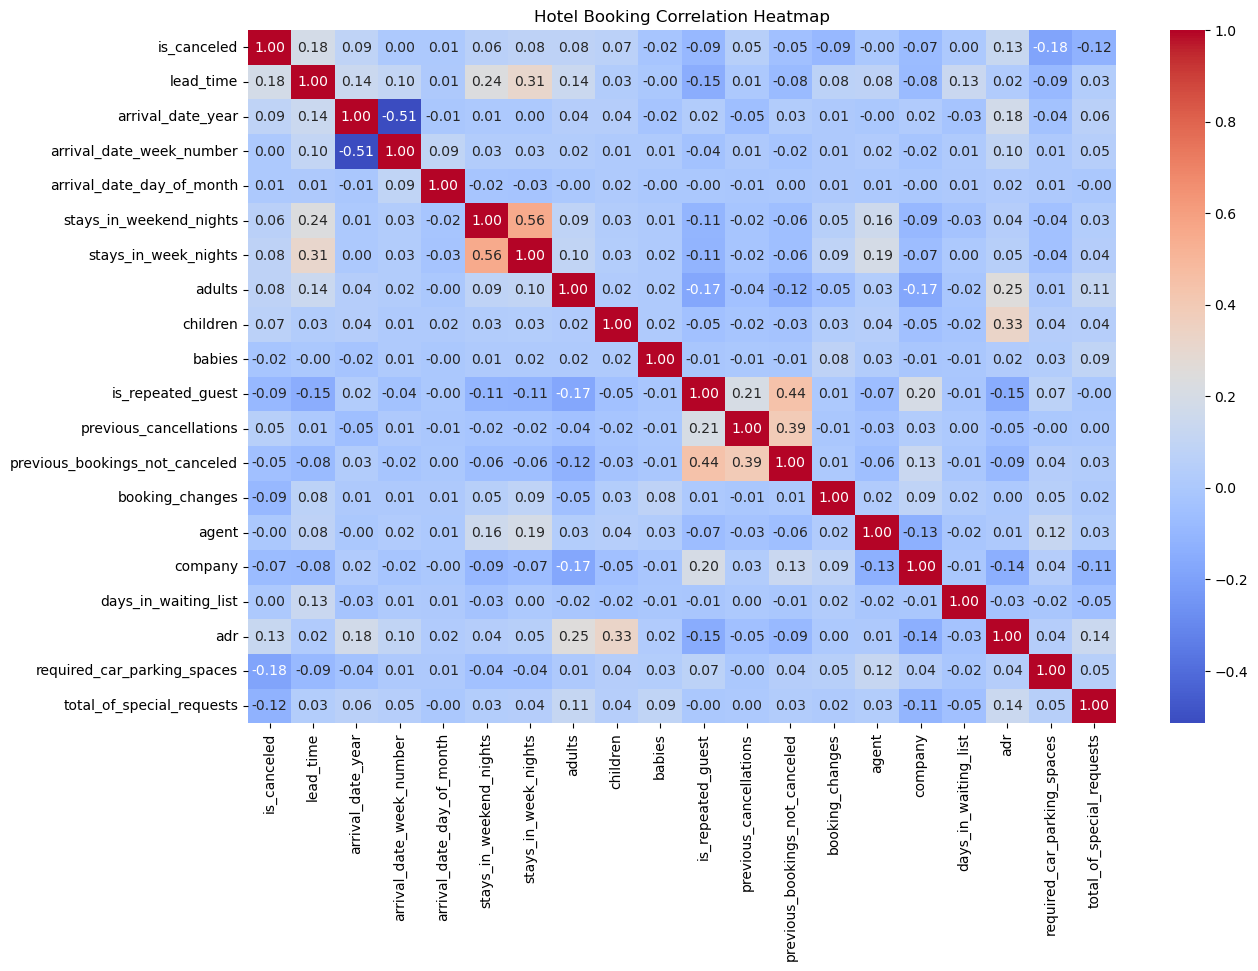

In [6]:
# Select numerical columns
corr = df.select_dtypes(include=np.number).corr()

# Display correlation
print(corr)

# Heatmap
plt.figure(figsize=(14,9))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')
plt.title("Hotel Booking Correlation Heatmap")
plt.show()

# Outlier detection

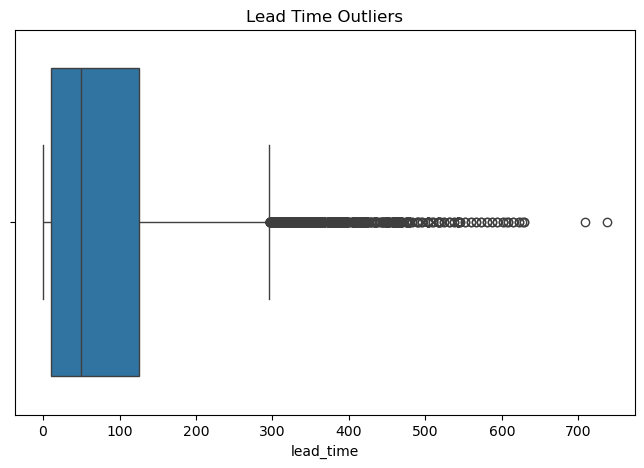

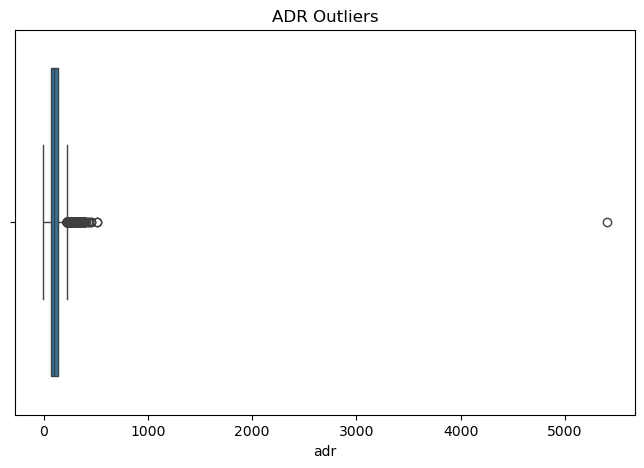

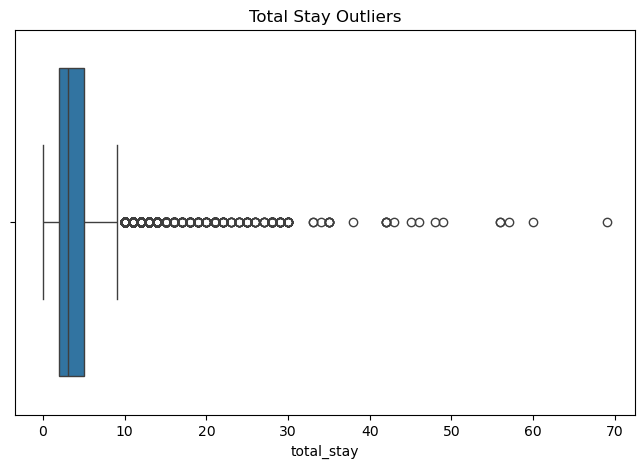

In [7]:
# Lead time outliers
plt.figure(figsize=(8,5))
sns.boxplot(x=df['lead_time'])
plt.title("Lead Time Outliers")
plt.show()

# Average daily rate outliers
plt.figure(figsize=(8,5))
sns.boxplot(x=df['adr'])
plt.title("ADR Outliers")
plt.show()

# Stay duration outliers
df['total_stay'] = (df['stays_in_weekend_nights'] +
                    df['stays_in_week_nights'])

plt.figure(figsize=(8,5))
sns.boxplot(x=df['total_stay'])
plt.title("Total Stay Outliers")
plt.show()

# Categorical analysis

In [8]:
# Bookings by hotel type
print(df['hotel'].value_counts())

# Bookings by meal type
print(df['meal'].value_counts())

# Bookings by market segment
print(df['market_segment'].value_counts())

# Average price by hotel type
print(df.groupby('hotel')['adr'].mean())

# Cancellation by customer type
print(df.groupby('customer_type')['is_canceled'].mean())

hotel
City Hotel      53428
Resort Hotel    33968
Name: count, dtype: int64
meal
BB           67978
SC            9481
HB            9085
Undefined      492
FB             360
Name: count, dtype: int64
market_segment
Online TA        51618
Offline TA/TO    13889
Direct           11804
Groups            4942
Corporate         4212
Complementary      702
Aviation           227
Undefined            2
Name: count, dtype: int64
hotel
City Hotel      110.985944
Resort Hotel     99.025346
Name: adr, dtype: float64
customer_type
Contract           0.163109
Group              0.099265
Transient          0.301059
Transient-Party    0.152383
Name: is_canceled, dtype: float64


# Monthly booking analysis

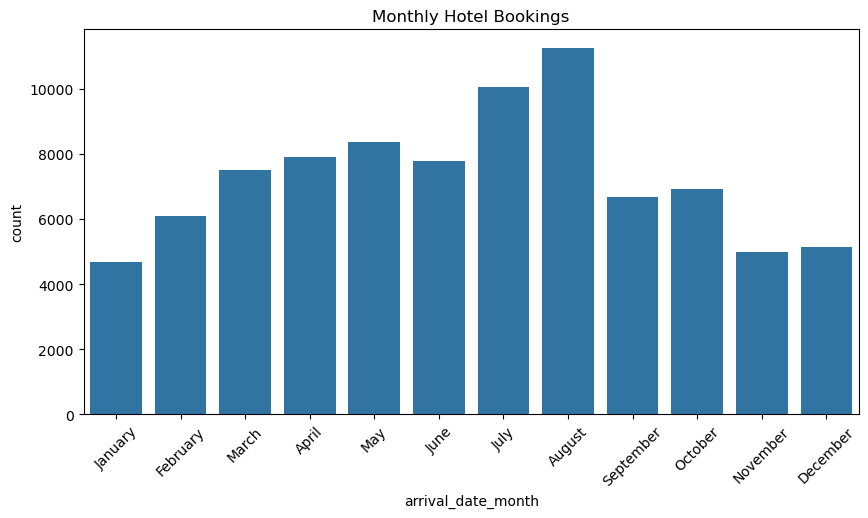

In [9]:
# Monthly bookings
plt.figure(figsize=(10,5))
sns.countplot(x='arrival_date_month',
              data=df,
              order=['January','February','March','April',
                     'May','June','July','August',
                     'September','October','November','December'])

plt.title("Monthly Hotel Bookings")
plt.xticks(rotation=45)
plt.show()

# Final statistical insights

In [10]:
print("Total Bookings:", len(df))

print("Total Cancellations:", df['is_canceled'].sum())

print("Cancellation Rate:",
      df['is_canceled'].mean() * 100)

print("Average Lead Time:", df['lead_time'].mean())

print("Average Daily Rate:", df['adr'].mean())

print("Average Stay Duration:", df['total_stay'].mean())

print("Most Common Hotel:", df['hotel'].mode()[0])

print("Most Common Customer Type:",
      df['customer_type'].mode()[0])

Total Bookings: 87396
Total Cancellations: 24025
Cancellation Rate: 27.489816467572886
Average Lead Time: 79.89136802599661
Average Daily Rate: 106.33724644148474
Average Stay Duration: 3.6306581536912446
Most Common Hotel: City Hotel
Most Common Customer Type: Transient


# HOTEL BOOKING DATA ANALYSIS – REPORT

Title: Exploratory Data Analysis on Hotel Booking Dataset

## 1. Introduction

The Hotel Booking Data Analysis project focuses on analysing hotel booking information using Python. The dataset contains booking details of City Hotels and Resort Hotels. The main aim is to understand booking patterns, cancellation rates, customer behaviour and hotel revenue.

## 2. Objectives

- To understand the hotel booking dataset.
- To clean missing and duplicate values.
- To analyse hotel booking distributions.
- To identify booking cancellation patterns.
- To study customer types and meal preferences.
- To identify relationships between numerical variables.
- To detect outliers in the dataset.

## 3. Tools and Technologies Used

- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Jupyter Notebook

## 4. Dataset Description

The dataset contains 1,19,390 rows and 32 columns before data cleaning.

It includes information such as:

- Hotel type
- Booking cancellation
- Lead time
- Arrival date
- Number of guests
- Meal type
- Market segment
- Customer type
- Average Daily Rate (ADR)
- Special requests

## 5. Data Cleaning

The following data-cleaning steps were performed:

1. Checked missing values.
2. Identified duplicate records.
3. Removed 31,994 duplicate records.
4. Filled missing children values using the median.
5. Replaced missing country values with 'Unknown'.
6. Filled missing agent and company values with -1.
7. Checked missing values again.

After cleaning, the dataset contained 87,396 records without missing values.

## 6. Univariate Analysis

Univariate analysis was performed to study individual variables.

- Hotel type distribution was analysed.
- Booking cancellation distribution was checked.
- Lead time distribution was visualized.
- Customer type distribution was analysed.

## 7. Bivariate Analysis

Bivariate analysis was performed to understand relationships between two variables.

- Hotel type vs booking cancellation.
- Lead time vs cancellation.
- Hotel type vs Average Daily Rate.
- Special requests vs cancellation.

This analysis helps understand factors related to booking cancellations.

## 8. Correlation Analysis

Correlation analysis was performed using numerical columns.

A heatmap was created to identify relationships between numerical variables.

Important observations:

- Lead time has a positive correlation with cancellation (0.185).
- Special requests have a negative correlation with cancellation (-0.121).
- Required car parking spaces have a negative correlation with cancellation (-0.184).

## 9. Outlier Detection

Outliers were identified using box plots for:

- Lead time
- Average Daily Rate (ADR)
- Total stay duration

These visualizations help identify unusually high or low values in the dataset.

## 10. Categorical Analysis

The categorical analysis produced the following results:

- City Hotel bookings: 53,428
- Resort Hotel bookings: 33,968
- Most common meal type: BB
- Most common market segment: Online TA
- Most common customer type: Transient

Average Daily Rate:

- City Hotel: 110.99
- Resort Hotel: 99.03

## 11. Monthly Booking Analysis

Monthly booking patterns were analysed using a count plot.

The graph helps understand the distribution of hotel arrivals across all twelve months.

## 12. Final Statistical Results

Total bookings

# 87,396

Total cancellations

# 24,025

Cancellation rate

# 27.49%

Average lead time

# 79.89 days

Average daily rate

# 106.34

Average stay duration

# 3.63 nights

Most common hotel: City Hotel

Most common customer type: Transient

## 13. Conclusion

The Hotel Booking Data Analysis project successfully analysed hotel booking information using Python libraries. Data cleaning, univariate analysis, bivariate analysis, correlation analysis and outlier detection were performed.

The analysis shows that City Hotel has more bookings than Resort Hotel. The most common customer type is Transient, and the overall booking cancellation rate is approximately 27.49%.

This project helps understand hotel booking patterns and customer behaviour. The insights can help hotels improve their booking management and customer services.

End of Report